In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

Load dataset

In [2]:
data = pd.read_csv('Data/Advertising.csv')
data.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


Preprocessing

In [3]:
data.describe()

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [4]:
data.columns

Index(['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='str')

In [5]:
data.shape

(200, 5)

In [6]:
data.size

1000

In [7]:
data.dtypes

Unnamed: 0      int64
TV            float64
Radio         float64
Newspaper     float64
Sales         float64
dtype: object

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [9]:
data.isna().sum()

Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(0)

Correlation analysis

In [11]:
correlation_matrix = data.corr()
correlation_matrix

,Unnamed: 0,TV,Radio,Newspaper,Sales
Unnamed: 0,1.000000,0.017715,-0.110680,-0.154944,-0.051616
TV,0.017715,1.000000,0.054809,0.056648,0.782224
Radio,-0.110680,0.054809,1.000000,0.354104,0.576223
Newspaper,-0.154944,0.056648,0.354104,1.000000,0.228299
Sales,-0.051616,0.782224,0.576223,0.228299,1.000000


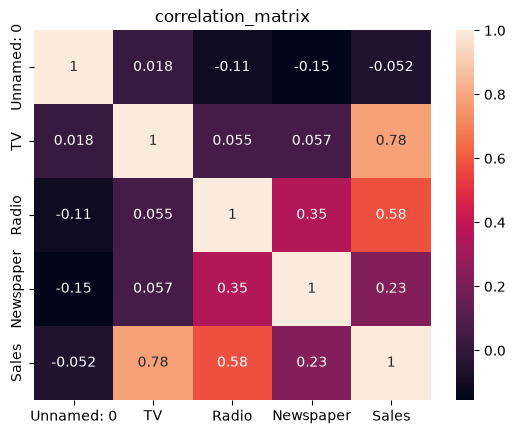

In [12]:
sns.heatmap(correlation_matrix, annot=True)
plt.title('correlation_matrix')
plt.show()

Data Visualization

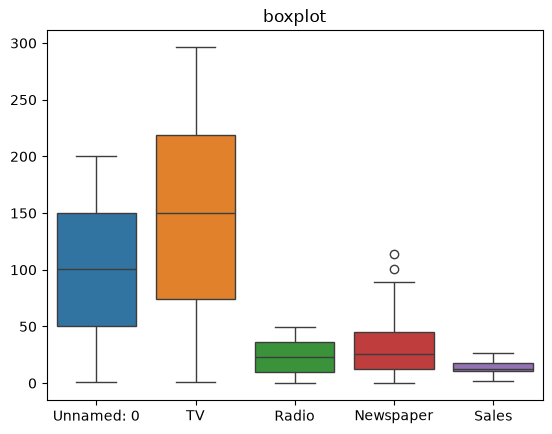

In [13]:
sns.boxplot(data=data)
plt.title('boxplot')
plt.show()

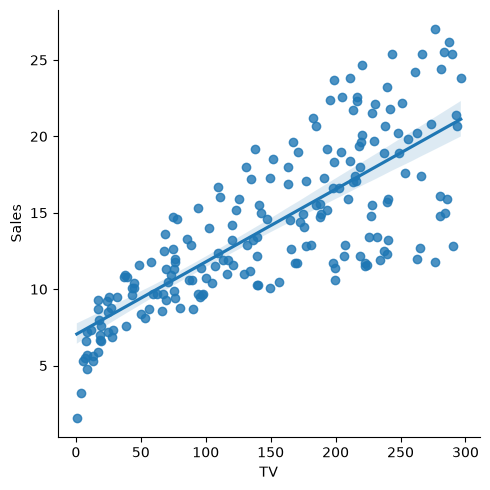

In [14]:
sns.lmplot(x='TV', y='Sales', data= data)
plt.show()

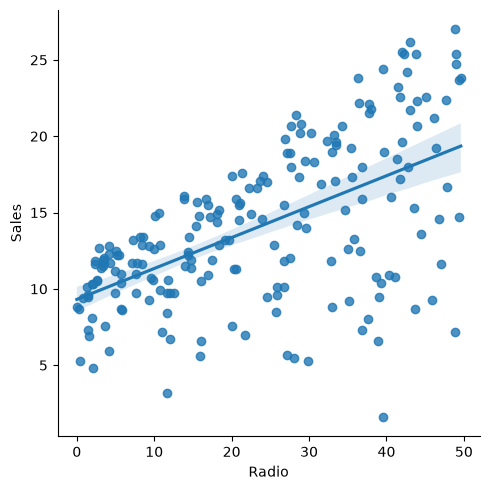

In [15]:
sns.lmplot(x='Radio', y='Sales', data= data)
plt.show()

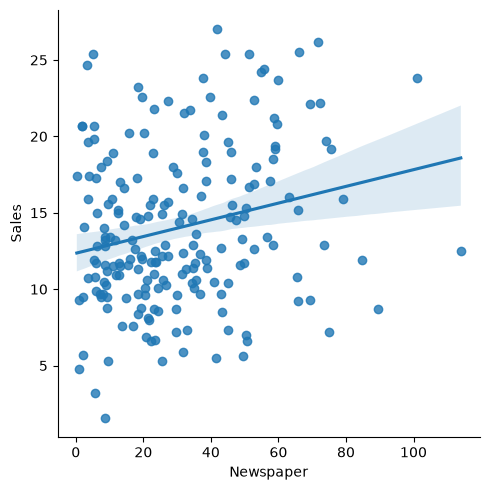

In [16]:
sns.lmplot(x='Newspaper', y='Sales', data= data)
plt.show()

Reshape the data to long format

In [17]:
df_long = pd.melt(data, id_vars=['Sales'], value_vars=['TV', 'Radio', 'Newspaper'],
                  var_name='Media', value_name='Spending')

All in one graph

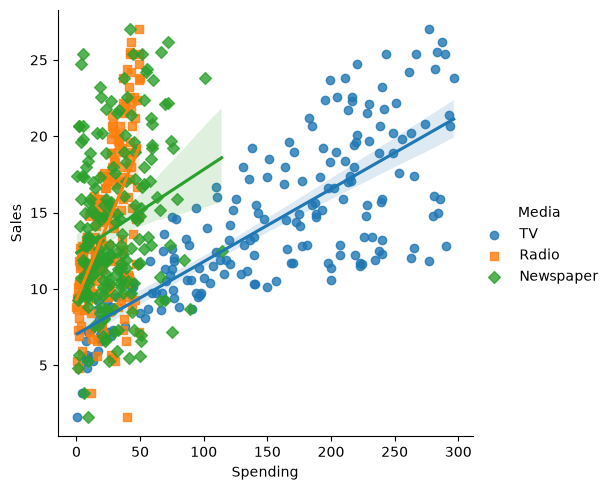

In [18]:
sns.lmplot(x='Spending', y='Sales', data=df_long, hue='Media', markers=['o','s', 'D'])

Spliting data into x and y

In [19]:
x= data[['TV', 'Radio', 'Newspaper']]
y= data[['Sales']]

In [20]:
x.head()

,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [21]:
y.head()

,Sales
0,22.1
1,10.4
2,9.3
3,18.5
4,12.9


Splitting data into test and train data

In [22]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.2) 

Linear Regression modeling

In [23]:
mlr = LinearRegression()

In [24]:
mlr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 3)","[[0.05,0.18,0. ]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[2.99]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


Predictions

In [25]:
y_pred = mlr.predict(x_test)
y_pred

array([[ 9.13482049],
       [22.71503307],
       [12.76619248],
       [21.6481132 ],
       [16.30067073],
       [11.67885601],
       [17.15000251],
       [23.15489755],
       [12.78143899],
       [19.84617785],
       [ 8.19201325],
       [11.99915557],
       [ 7.83355098],
       [20.11774327],
       [15.46099543],
       [13.96791355],
       [ 9.87951579],
       [10.08899042],
       [ 9.65965414],
       [13.06084719],
       [17.22535563],
       [23.07371532],
       [14.90318017],
       [18.24369715],
       [10.0288731 ],
       [14.72433908],
       [11.57603319],
       [12.25119514],
       [13.40685295],
       [16.51554561],
       [10.20496754],
       [ 6.66256953],
       [17.04622662],
       [23.94200113],
       [24.54969323],
       [ 8.3048719 ],
       [16.70058389],
       [ 8.13081276],
       [12.36627883],
       [19.05120056]])

Model Coefficient and intercept m, c -- calculation

In [26]:
print('coe:', mlr.coef_)
print('inter:', mlr.intercept_)

coe: [[0.04579729 0.18135465 0.00032375]]
inter: [2.98664832]


Visualisation of actual and predicted values

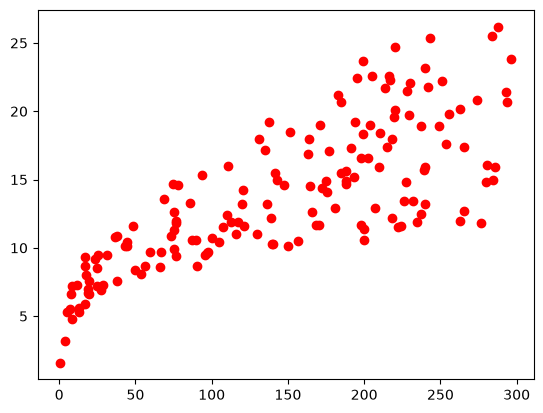

In [27]:
plt.scatter(x_train['TV'], y_train, color='red')


Perormance metrics for regression model(MAE, MSE, RMSE)

In [28]:
print(mean_absolute_error(y_test, y_pred))
print(mean_squared_error(y_test, y_pred))
print(np.sqrt(mean_squared_error(y_test, y_pred)))

1.2250706569044318
2.277504518973015
1.509140324480469


Creating Dataframe to view result

In [29]:
Results = pd.DataFrame(columns=['Actual_Sales', 'Predicted_sales'])
Results['Actual_Sales'] = y_test
Results['Predicted_sales'] = y_pred
Results.head()

,Actual_Sales,Predicted_sales
29,10.5,9.134820
61,24.2,22.715033
16,12.5,12.766192
58,23.8,21.648113
194,17.3,16.300671


Calculate r2 value

In [30]:
r2 = r2_score(y_test, y_pred)
r2

0.9210043091943122

Conclusion

Based on the results from Multiple Liner Regression(MLR) model, the R2value of 0.9182 indicates that approximately 91.82% of the variance in the dependant variable(Sales) can be explained by the independent variables used in the model.
This is a strong indication that the model is well-fiiting and has high predictive power.

The multiple linear regression model explains 91.82% of the variance in the sales data, which is a good result. However, the prediction errors indicate that there might be room for improvemnet, particularly for higher sales values.

Overall, the model demonstrates a strong ability to predict sales based on the available features, with the R2 value confirming its effectiveness. However, there may still be potential for further model refinement, such as through feature engineering,addressing any outliers, or trying more complex models, to reduce the small prediction errors seen in certain instances.